In [1]:

import nbimporter
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

%matplotlib inline

functions = nbimporter.NotebookLoader().load_module("functions")


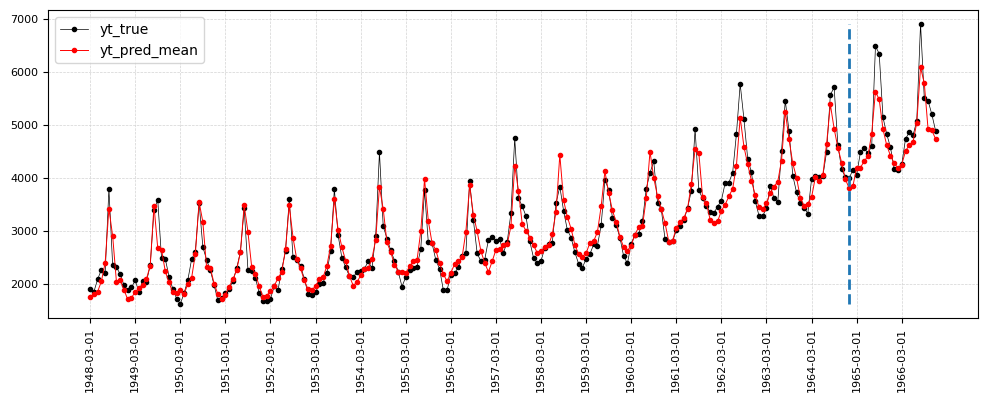

In [7]:

# Promedio de los pronosticos
df_orig = pd.read_csv("../submission/forecasts.csv")
df_dropna = df_orig.dropna().copy()
df_dropna = df_dropna.set_index("date")

columnas_modelos = [
    col for col in df_dropna.columns
    if col.startswith("yt_pred_")
]

df_dropna["yt_pred_mean"] = df_dropna[columnas_modelos].mean(axis=1)

functions.plot_time_series(
    df=df_dropna[["yt_true", "yt_pred_mean"]],
    yt_col="yt_true"
)

plt.show()


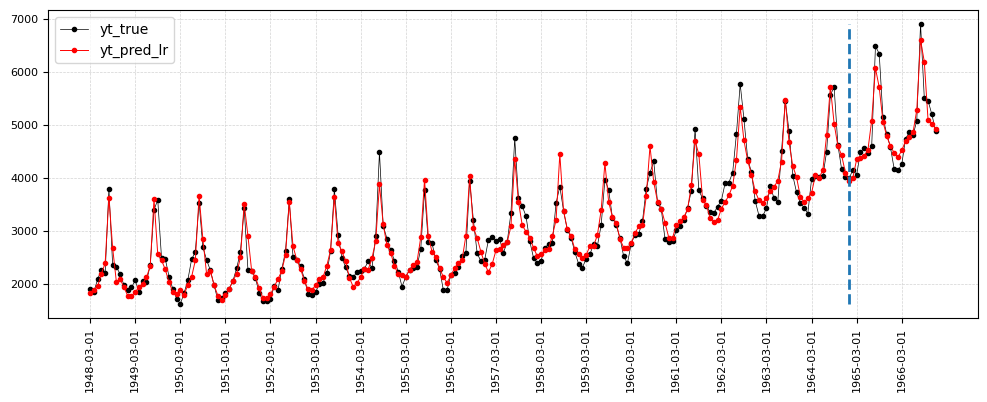

In [8]:
model = LinearRegression()
X = df_dropna.drop(columns=["yt_true", "yt_pred_mean"])
y = df_dropna["yt_true"]
model.fit(X, y)
df_dropna["yt_pred_lr"] = model.predict(X)
functions.plot_time_series(df=df_dropna[["yt_true", "yt_pred_lr"]], yt_col="yt_true")

In [4]:

import pandas as pd

forecasts = pd.read_csv("../submission/forecasts.csv")
metrics = pd.read_csv("../submission/metrics.csv")

print("COLUMNAS DE PRONÓSTICOS:")
print(forecasts.columns.tolist())

print("\nCOLUMNAS DE MÉTRICAS:")
print(metrics.columns.tolist())

print("\nDIMENSIONES:")
print("Pronósticos:", forecasts.shape)
print("Métricas:", metrics.shape)


COLUMNAS DE PRONÓSTICOS:
['date', 'yt_pred_time_trend_1_dummy', 'yt_pred_time_trend_2_dummy', 'yt_pred_time_trend_3_dummy', 'yt_true', 'yt_pred_time_trend_3_fourier', 'yt_pred_mlp_8', 'yt_pred_stacked_mlp', 'yt_pred_d1d13_ar13', 'yt_pred_d1d12_mlp']

COLUMNAS DE MÉTRICAS:
['Metrics', 'yt_pred_time_trend_1_dummy', 'yt_pred_time_trend_2_dummy', 'yt_pred_time_trend_3_dummy', 'yt_pred_time_trend_3_fourier', 'yt_pred_mlp_8', 'yt_pred_stacked_mlp', 'yt_pred_d1d13_ar13', 'yt_pred_d1d12_mlp']

DIMENSIONES:
Pronósticos: (252, 10)
Métricas: (4, 9)


In [5]:
import pandas as pd

df = pd.read_csv("../submission/forecasts.csv")

columnas_modelos = [
    col for col in df.columns
    if col.startswith("yt_pred_")
]

print("Modelos que deben entrar al promedio:")
print(columnas_modelos)

print("\nNúmero de modelos:", len(columnas_modelos))
print("¿Se incluyó yt_true?", "yt_true" in columnas_modelos)

Modelos que deben entrar al promedio:
['yt_pred_time_trend_1_dummy', 'yt_pred_time_trend_2_dummy', 'yt_pred_time_trend_3_dummy', 'yt_pred_time_trend_3_fourier', 'yt_pred_mlp_8', 'yt_pred_stacked_mlp', 'yt_pred_d1d13_ar13', 'yt_pred_d1d12_mlp']

Número de modelos: 8
¿Se incluyó yt_true? False
